In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from datasets import load_dataset

In [10]:
emotion_dataset = load_dataset('dair-ai/emotion')
# https://huggingface.co/datasets/dair-ai/emotion
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']
test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [11]:
df_train = pd.DataFrame(
    {
        'text' :train_text,
        'label': [label_names[i] for i in train_label]
    }
)
df_test = pd.DataFrame(
    {
        'text' :test_text,
        'label': [label_names[i] for i in test_label]
    }
)

In [12]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [13]:
train_label

Column([0, 0, 3, 2, 3, ...])

In [7]:
label_names = emotion_dataset['train'].features['label'].names

In [8]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [9]:
for i in train_label:
  print(label_names[i])

Streaming output truncated to the last 5000 lines.
sadness
sadness
anger
fear
love
joy
anger
sadness
sadness
joy
fear
joy
fear
love
love
anger
anger
sadness
fear
sadness
sadness
surprise
love
joy
joy
love
sadness
joy
joy
fear
sadness
anger
anger
sadness
love
fear
fear
anger
anger
joy
sadness
sadness
joy
joy
fear
sadness
joy
love
fear
anger
sadness
joy
anger
surprise
fear
joy
joy
love
fear
sadness
joy
anger
fear
anger
sadness
sadness
sadness
anger
sadness
fear
joy
anger
anger
sadness
fear
joy
anger
fear
sadness
joy
fear
joy
love
anger
fear
fear
fear
fear
joy
anger
anger
sadness
joy
sadness
joy
sadness
sadness
joy
sadness
fear
fear
joy
sadness
joy
sadness
joy
fear
anger
sadness
joy
anger
joy
joy
sadness
joy
joy
anger
anger
joy
joy
joy
sadness
joy
joy
joy
anger
anger
joy
love
joy
love
joy
joy
joy
sadness
joy
sadness
surprise
sadness
anger
anger
anger
fear
fear
joy
fear
fear
joy
anger
joy
joy
joy
love
joy
fear
sadness
sadness
surprise
sadness
sadness
anger
joy
love
fear
joy
anger
joy
surpr

EDA

In [14]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

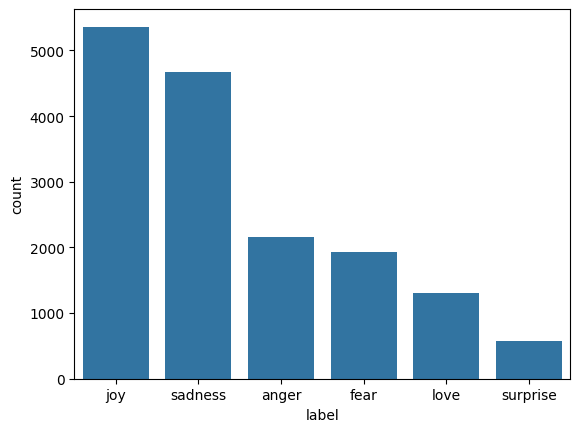

In [15]:
sns.countplot(x='label', data=df_train, order=df_train['label'].value_counts().index)

DATA PREPROCESSSING
Using NLP


In [16]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
max_words = 10000

tokenizer = Tokenizer(num_words=max_words, oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])
train_sequences = tokenizer.texts_to_sequences(df_train['text'])
test_sequences = tokenizer.texts_to_sequences(df_test['text'])

padded_train_sequences = pad_sequences(train_sequences, maxlen=50, padding='post', truncating='post')
padded_test_sequences = pad_sequences(test_sequences, maxlen=50, padding='post', truncating='post')

train_label = np.array(train_label)
test_label = np.array(test_label)

num_classes = len(np.unique(train_label))
num_classes
print(f"Vocabulary Size:{len(tokenizer.word_index)}")
print(f"Max Sentence Length:{padded_train_sequences.shape[1]}")

Vocabulary Size:15213
Max Sentence Length:50


Shared Training Utilities

In [17]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(train_label),
    y=train_label
)
class_weight_dict = dict(enumerate(class_weights))

In [18]:
from tensorflow.keras.callbacks import EarlyStopping
earlyStopping = EarlyStopping(
monitor='val_loss',
patience=3,
restore_best_weights=True
)

Phase 1 - PLAIN FOUNDATIONAL MODELS


---
MOdel 1 Simple RNN



---



In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense,Dropout, LSTM ,GRU

rnn_model = Sequential(
    [
        Embedding(input_dim = max_words, output_dim =128 ,input_length=50),
        SimpleRNN(units=128, return_sequences=True),
        Dropout(0.5),
        SimpleRNN(units=64),
        Dense(units=num_classes, activation='softmax') #Output

    ]
)
rnn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [20]:
rnn_model.fit(
    padded_train_sequences,
    train_label,
    validation_data= (padded_test_sequences, test_label),
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    class_weight= class_weight_dict,
    callbacks=[earlyStopping]
)
rnn_loss, rnn_accuracy = rnn_model.evaluate(padded_test_sequences, test_label)
print(f"RNN Loss: {rnn_loss}")
print(f"RNN Accuracy: {rnn_accuracy}")

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 26s 44ms/step - accuracy: 0.1598 - loss: 1.8826 - val_accuracy: 0.0795 - val_loss: 1.8915
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 46ms/step - accuracy: 0.1469 - loss: 1.8192 - val_accuracy: 0.0795 - val_loss: 1.7742
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 23s 45ms/step - accuracy: 0.1441 - loss: 1.7993 - val_accuracy: 0.1120 - val_loss: 1.7767
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 42s 48ms/step - accuracy: 0.1315 - loss: 1.8011 - val_accuracy: 0.0330 - val_loss: 1.8077
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 41s 47ms/step - accuracy: 0.1443 - loss: 1.8008 - val_accuracy: 0.0795 - val_loss: 1.7952
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.0795 - loss: 1.7742
RNN Loss: 1.7742313146591187
RNN Accuracy: 0.0794999971985817


In [21]:
lstm_model = Sequential(
    [
        Embedding(input_dim = max_words, output_dim =128 ,input_length=50),
        LSTM(units=128, return_sequences=True),
        Dropout(0.5),
        LSTM(units=64),
        Dense(units=num_classes, activation='softmax') #Output

    ]
)
lstm_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
lstm_model.fit(
    padded_train_sequences,
    train_label,
    validation_data= (padded_test_sequences, test_label),
    epochs=20,
    batch_size=32,
    class_weight= class_weight_dict,
    callbacks=[earlyStopping]
)
lstm_loss, lstm_accuracy = lstm_model.evaluate(padded_test_sequences, test_label)
print(f"RNN Loss: {lstm_loss}")
print(f"RNN Accuracy: {lstm_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 62s 118ms/step - accuracy: 0.1857 - loss: 1.7937 - val_accuracy: 0.1250 - val_loss: 1.7863
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 118ms/step - accuracy: 0.1452 - loss: 1.7927 - val_accuracy: 0.0515 - val_loss: 1.7920
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 58s 117ms/step - accuracy: 0.1671 - loss: 1.7946 - val_accuracy: 0.0345 - val_loss: 1.8010
63/63 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.1250 - loss: 1.7863
RNN Loss: 1.7862550020217896
RNN Accuracy: 0.125


In [22]:
gru_model = Sequential(
    [
        Embedding(input_dim = max_words, output_dim =128 ,input_length=50),
        GRU(units=128, return_sequences=True),
        Dropout(0.5),
        GRU(units=64),
        Dense(units=num_classes, activation='softmax') #Output

    ]
)
gru_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
gru_model.fit(
    padded_train_sequences,
    train_label,
    validation_data= (padded_test_sequences, test_label),
    epochs=20,
    batch_size=32,
    # validation_split=0.2,
    class_weight= class_weight_dict,
    callbacks=[earlyStopping]
)
gru_loss, gru_accuracy = gru_model.evaluate(padded_test_sequences, test_label)
print(f"RNN Loss: {gru_loss}")
print(f"RNN Accuracy: {gru_accuracy}")


Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 53s 99ms/step - accuracy: 0.1238 - loss: 1.7946 - val_accuracy: 0.2910 - val_loss: 1.7739
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 82s 100ms/step - accuracy: 0.1624 - loss: 1.7934 - val_accuracy: 0.3475 - val_loss: 1.7679
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 49s 97ms/step - accuracy: 0.2041 - loss: 1.7926 - val_accuracy: 0.2880 - val_loss: 1.7797
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 50s 100ms/step - accuracy: 0.1762 - loss: 1.7888 - val_accuracy: 0.2790 - val_loss: 1.7870
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 81s 98ms/step - accuracy: 0.1872 - loss: 1.7660 - val_accuracy: 0.3260 - val_loss: 1.7904
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.3475 - loss: 1.7679
RNN Loss: 1.7678929567337036
RNN Accuracy: 0.3474999964237213


**Ranking & Selection **
Rank foundational models to pick the best base cell for phase 2

In [23]:
result_df = pd.DataFrame(
    {
        'Model': ['RNN', 'LSTM', 'GRU'],
        'Loss': [rnn_loss, lstm_loss, gru_loss],
        'Accuracy': [rnn_accuracy, lstm_accuracy, gru_accuracy]
    }).sort_values(by='Accuracy', ascending=False)
result_df

,Model,Loss,Accuracy
2,GRU,1.767893,0.3475
1,LSTM,1.786255,0.1250
0,RNN,1.774231,0.0795


**Phase 2- Advanced Biderectional GRU**

In [25]:
 from tensorflow.keras.layers import Bidirectional
 BiGRU = Sequential([
     Embedding(input_dim=max_words, output_dim=300, input_length=50),
     Bidirectional(GRU(units=128, return_sequences=True)),
     Dropout(0.5),
     Bidirectional(GRU(units=64)),
     Dropout(0.5),
     Dense(units=num_classes, activation='softmax')
 ])

 BiGRU.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
 BiGRU.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [26]:
BiGRU.fit(
    padded_train_sequences,
    train_label,
    validation_data= (padded_test_sequences, test_label),
    epochs=20,
    batch_size=32,
    # validation_split=0.2,
    class_weight= class_weight_dict,
    callbacks=[earlyStopping]
)

Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 144s 275ms/step - accuracy: 0.5759 - loss: 0.9963 - val_accuracy: 0.8945 - val_loss: 0.3540
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 159s 309ms/step - accuracy: 0.9159 - loss: 0.2402 - val_accuracy: 0.9115 - val_loss: 0.2812
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 166s 332ms/step - accuracy: 0.9451 - loss: 0.1580 - val_accuracy: 0.9265 - val_loss: 0.2220
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 166s 332ms/step - accuracy: 0.9600 - loss: 0.1118 - val_accuracy: 0.9215 - val_loss: 0.2325
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 196s 321ms/step - accuracy: 0.9651 - loss: 0.0990 - val_accuracy: 0.9270 - val_loss: 0.2526
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 153s 307ms/step - accuracy: 0.9778 - loss: 0.0675 - val_accuracy: 0.9180 - val_loss: 0.2561


In [27]:
BiGRU_loss, BiGRU_accuracy = BiGRU.evaluate(padded_test_sequences, test_label)
print(f"RNN Loss: {BiGRU_loss}")
print(f"RNN Accuracy: {BiGRU_accuracy}")

63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - accuracy: 0.9265 - loss: 0.2220
RNN Loss: 0.22200800478458405
RNN Accuracy: 0.9265000224113464


Overall Evaluation & Bias Analysis
Confusion Matrix


63/63 ━━━━━━━━━━━━━━━━━━━━ 4s 59ms/step


<Axes: >

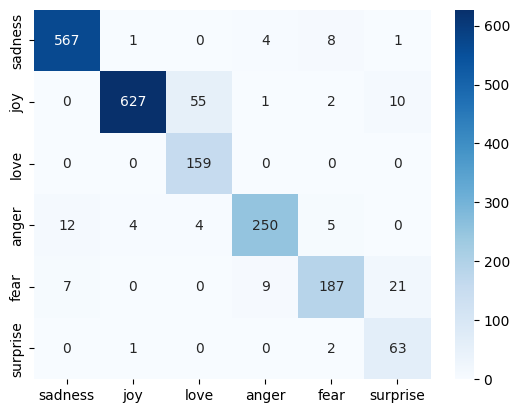

In [34]:
from sklearn.metrics import confusion_matrix
BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequences),axis=1)
sns.heatmap(confusion_matrix(test_label, BiGRU_predictions), annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)

#

Final Prediction

In [38]:
sample_text = [
    "I feel lonely even when I am surrounded by people.",
    "Being with you makes me feel complete.",
    "I am extremely frustrated with your behaviour.",
    "I don't know what will happen tomorrow.",
    "I can't believe you actually did that!"
]
sample_sequences = tokenizer.texts_to_sequences(sample_text)
sample_padded_sequences = pad_sequences(sample_sequences, maxlen=50, padding='post', truncating='post')
sample_predictions = np.argmax(BiGRU.predict(sample_padded_sequences),axis=1)

for i in range(len(sample_text)):
  print(f"Text: {sample_text[i]} \nPredicted Emotion: {label_names[sample_predictions[i]]}")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
Text: I feel lonely even when I am surrounded by people. 
Predicted Emotion: sadness
Text: Being with you makes me feel complete. 
Predicted Emotion: love
Text: I am extremely frustrated with your behaviour. 
Predicted Emotion: anger
Text: I don't know what will happen tomorrow. 
Predicted Emotion: anger
Text: I can't believe you actually did that! 
Predicted Emotion: sadness


Save Model & Tokenizer

In [45]:
import os
import pickle
model_dir = 'Artifacts'
os.makedirs(model_dir,exist_ok=True)

#Save our BiGRU mODEL
BiGRU.save(os.path.join(model_dir,'BiGRU_Model.keras'))
#Save the tokenizer model
with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)